In [1]:
!pip install -q effdet timm albumentations pycocotools

In [2]:
import os
import glob
import zipfile
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2

from effdet import get_efficientdet_config, EfficientDet, DetBenchPredict
from effdet.efficientdet import HeadNet

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cuda
PyTorch version: 2.11.0+cu130


In [3]:
# ==========================================
# FIND TFP-BD DATASET
# ==========================================

INPUT_DATASET_PATH = None

for root, dirs, files in os.walk("/kaggle/input"):
    if (
        os.path.basename(root) == "tfp_dataset"
        and os.path.isdir(os.path.join(root, "test", "images"))
    ):
        INPUT_DATASET_PATH = root
        break

if INPUT_DATASET_PATH is None:
    raise FileNotFoundError(
        "tfp_dataset not found. Please attach the dataset to this Kaggle Notebook."
    )

TEST_IMG_DIR = os.path.join(
    INPUT_DATASET_PATH, "test", "images"
)

TEST_LABEL_DIR = os.path.join(
    INPUT_DATASET_PATH, "test", "labels"
)

print("Dataset:", INPUT_DATASET_PATH)
print("Test images:", TEST_IMG_DIR)
print("Test labels:", TEST_LABEL_DIR)

if not os.path.isdir(TEST_LABEL_DIR):
    raise FileNotFoundError(
        "Test labels folder not found. Check your dataset structure."
    )

Dataset: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Test images: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Test labels: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/labels


In [4]:
# ==========================================
# FIND EFFICIENTDET-D3 CHECKPOINT
# ==========================================

weights_path = None
unzipped_weights_dir = None

# First search for the exact checkpoint filename
for root, dirs, files in os.walk("/kaggle/input"):
    if "effdet_d3_epoch_30.pth" in files:
        weights_path = os.path.join(
            root, "effdet_d3_epoch_30.pth"
        )
        break

# Search for other .pth files if exact name is unavailable
if weights_path is None:
    for root, dirs, files in os.walk("/kaggle/input"):
        for file in files:
            if (
                file.endswith(".pth")
                and "effdet" in root.lower()
                and "d3" in root.lower()
            ):
                weights_path = os.path.join(root, file)
                break

        if weights_path:
            break

# Search for extracted PyTorch checkpoint
if weights_path is None:
    for root, dirs, files in os.walk("/kaggle/input"):
        if "data.pkl" in files and "version" in files:
            if "effdet" in root.lower() or "d3" in root.lower():
                unzipped_weights_dir = root
                break

if weights_path is None and unzipped_weights_dir is None:
    raise FileNotFoundError(
        "EfficientDet-D3 checkpoint not found. "
        "Attach the trained model dataset to this notebook."
    )

# Rebuild checkpoint if only extracted files are available
if weights_path is None:

    print("Extracted checkpoint found:", unzipped_weights_dir)

    weights_path = (
        "/kaggle/working/effdet_d3_epoch_30_fixed.pth"
    )

    with zipfile.ZipFile(
        weights_path,
        "w",
        compression=zipfile.ZIP_STORED
    ) as zf:

        for root, dirs, files in os.walk(unzipped_weights_dir):

            for file in files:

                full_path = os.path.join(root, file)

                relative_path = os.path.relpath(
                    full_path,
                    unzipped_weights_dir
                )

                archive_name = os.path.join(
                    "archive",
                    relative_path
                )

                zf.write(full_path, archive_name)

    print("Checkpoint rebuilt successfully.")

else:
    print("Checkpoint file found:", weights_path)

Extracted checkpoint found: /kaggle/input/datasets/sharminaktermukta/efficientnetd3-30-epoch/effdet_d3_epoch_30
Checkpoint rebuilt successfully.


In [5]:
# ==========================================
# LOAD EFFICIENTDET-D3 MODEL
# ==========================================

CLASSES = [
    "Car",
    "Bus",
    "Truck",
    "Motorcycle",
    "Bicycle",
    "Rickshaw",
    "Mini-Truck",
    "CNG",
    "Pedestrian"
]

NUM_CLASSES = len(CLASSES)
IMG_SIZE = 640

config = get_efficientdet_config("tf_efficientdet_d3")

config.image_size = (IMG_SIZE, IMG_SIZE)
config.num_classes = NUM_CLASSES

net = EfficientDet(
    config,
    pretrained_backbone=False
)

net.class_net = HeadNet(
    config,
    num_outputs=NUM_CLASSES
)

checkpoint = torch.load(
    weights_path,
    map_location=device,
    weights_only=False
)

# Support common checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]

elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]

else:
    state_dict = checkpoint

net.load_state_dict(state_dict)

bench = DetBenchPredict(net)

bench.to(device)
bench.eval()

print("EfficientDet-D3 loaded successfully!")
print("Model ready for PCU evaluation.")

EfficientDet-D3 loaded successfully!
Model ready for PCU evaluation.


In [6]:
# ==========================================
# COMMON PCU CONFIGURATION
# ==========================================

pcu_weights = {
    "Car": 1.0,
    "Bus": 3.0,
    "Truck": 3.0,
    "Mini-Truck": 1.5,
    "CNG": 0.75,
    "Motorcycle": 0.4,
    "Rickshaw": 0.8,
    "Bicycle": 0.3,
    "Pedestrian": 0.0
}

LOW_THRESHOLD = 8.45
HIGH_THRESHOLD = 15.80
CONF_THRESHOLD = 0.30

# Prediction class mapping
# IMPORTANT: This follows your previous notebook's 1-based mapping.
class_mapping = {
    1: "Car",
    2: "Bus",
    3: "Truck",
    4: "Motorcycle",
    5: "Bicycle",
    6: "Rickshaw",
    7: "Mini-Truck",
    8: "CNG",
    9: "Pedestrian"
}

def get_congestion_level(total_pcu):

    if total_pcu < LOW_THRESHOLD:
        return "Low"

    elif total_pcu <= HIGH_THRESHOLD:
        return "Medium"

    else:
        return "High"


print("PCU configuration loaded.")
print("Low threshold:", LOW_THRESHOLD)
print("High threshold:", HIGH_THRESHOLD)
print("Confidence threshold:", CONF_THRESHOLD)

PCU configuration loaded.
Low threshold: 8.45
High threshold: 15.8
Confidence threshold: 0.3


In [7]:
# ==========================================
# CHECK PREDICTION CLASS IDS
# ==========================================

sample_images = sorted(
    glob.glob(os.path.join(TEST_IMG_DIR, "*.*"))
)

if len(sample_images) == 0:
    raise ValueError("No test images found.")

def preprocess_image(image_path):

    img_bgr = cv2.imread(image_path)

    if img_bgr is None:
        raise ValueError(f"Cannot read image: {image_path}")

    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    transform = A.Compose([
        A.Resize(
            height=IMG_SIZE,
            width=IMG_SIZE
        ),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        ),
        ToTensorV2()
    ])

    tensor_img = transform(
        image=img_rgb
    )["image"].unsqueeze(0).to(device)

    return img_rgb, tensor_img


def get_model_outputs(image_path):

    img_rgb, tensor_img = preprocess_image(image_path)

    img_info = {
        "img_scale": torch.tensor(
            [1.0],
            dtype=torch.float32,
            device=device
        ),

        "img_size": torch.tensor(
            [[IMG_SIZE, IMG_SIZE]],
            dtype=torch.float32,
            device=device
        )
    }

    with torch.no_grad():

        outputs = bench(
            tensor_img,
            img_info
        )[0]

    return img_rgb, outputs


sample_rgb, sample_outputs = get_model_outputs(
    sample_images[0]
)

sample_valid = sample_outputs[
    sample_outputs[:, 4] >= CONF_THRESHOLD
]

if len(sample_valid) > 0:

    observed_ids = sorted(
        set(
            int(x)
            for x in sample_valid[:, 5].cpu().numpy()
        )
    )

    print("Observed prediction class IDs:", observed_ids)

else:
    print("No detection found above confidence threshold in this sample.")

print("Current class mapping:", class_mapping)

Observed prediction class IDs: [1, 2, 6, 8, 9]
Current class mapping: {1: 'Car', 2: 'Bus', 3: 'Truck', 4: 'Motorcycle', 5: 'Bicycle', 6: 'Rickshaw', 7: 'Mini-Truck', 8: 'CNG', 9: 'Pedestrian'}


In [8]:
# ==========================================
# GROUND TRUTH PCU CALCULATION
# ==========================================

def calculate_gt_pcu(label_path):

    total_pcu = 0.0

    with open(label_path, "r") as file:

        lines = file.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) < 5:
            continue

        # YOLO ground truth class IDs: 0 to 8
        class_id = int(float(values[0]))

        if class_id < 0 or class_id >= len(CLASSES):

            raise ValueError(
                f"Invalid ground truth class ID: {class_id}"
            )

        class_name = CLASSES[class_id]

        total_pcu += pcu_weights[class_name]

    return total_pcu


print("Ground Truth PCU function ready.")

Ground Truth PCU function ready.


In [9]:
# ==========================================
# PREDICTED PCU CALCULATION
# ==========================================

def calculate_pred_pcu(image_path):

    img_rgb, outputs = get_model_outputs(image_path)

    predictions = outputs[
        outputs[:, 4] >= CONF_THRESHOLD
    ]

    total_pcu = 0.0

    for pred in predictions:

        class_id = int(pred[5].item())

        if class_id not in class_mapping:

            raise ValueError(
                f"Unknown prediction class ID: {class_id}. "
                "Check Cell 7 and the model's training label convention."
            )

        class_name = class_mapping[class_id]

        if class_name != "Pedestrian":

            total_pcu += pcu_weights[class_name]

    return total_pcu


print("Prediction PCU function ready.")

Prediction PCU function ready.


In [10]:
# ==========================================
# FULL TEST DATASET PCU EVALUATION
# ==========================================

test_images = sorted(
    glob.glob(os.path.join(TEST_IMG_DIR, "*.*"))
)

print("Total test images:", len(test_images))

if len(test_images) == 0:
    raise ValueError("No test images found.")

y_true = []
y_pred = []

evaluation_rows = []

for i, image_path in enumerate(test_images):

    image_name = os.path.basename(image_path)

    label_name = (
        os.path.splitext(image_name)[0] + ".txt"
    )

    label_path = os.path.join(
        TEST_LABEL_DIR,
        label_name
    )

    if not os.path.isfile(label_path):

        raise FileNotFoundError(
            f"Missing ground truth label: {label_path}"
        )

    # Ground Truth PCU
    gt_pcu = calculate_gt_pcu(label_path)

    gt_level = get_congestion_level(gt_pcu)

    # Predicted PCU
    pred_pcu = calculate_pred_pcu(image_path)

    pred_level = get_congestion_level(pred_pcu)

    y_true.append(gt_level)
    y_pred.append(pred_level)

    evaluation_rows.append({

        "image_name": image_name,

        "ground_truth_pcu": gt_pcu,

        "predicted_pcu": pred_pcu,

        "actual_congestion": gt_level,

        "predicted_congestion": pred_level

    })

    if (i + 1) % 100 == 0:

        print(
            f"Processed {i + 1}/{len(test_images)} images"
        )


results_df = pd.DataFrame(evaluation_rows)

print("\nEvaluation completed!")
print("Total evaluated images:", len(results_df))

display(results_df.head())

Total test images: 2368
Processed 100/2368 images
Processed 200/2368 images
Processed 300/2368 images
Processed 400/2368 images
Processed 500/2368 images
Processed 600/2368 images
Processed 700/2368 images
Processed 800/2368 images
Processed 900/2368 images
Processed 1000/2368 images
Processed 1100/2368 images
Processed 1200/2368 images
Processed 1300/2368 images
Processed 1400/2368 images
Processed 1500/2368 images
Processed 1600/2368 images
Processed 1700/2368 images
Processed 1800/2368 images
Processed 1900/2368 images
Processed 2000/2368 images
Processed 2100/2368 images
Processed 2200/2368 images
Processed 2300/2368 images

Evaluation completed!
Total evaluated images: 2368


,image_name,ground_truth_pcu,predicted_pcu,actual_congestion,predicted_congestion
0,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd...,14.55,15.35,Medium,Medium
1,frame0_jpg.rf.47f88bfa8857bb079cdaaffe6aa6ecd2...,27.90,21.95,High,High
2,frame0_jpg.rf.9067d8476599d820a5497e7a4933764d...,15.25,12.65,Medium,Medium
3,frame0_jpg.rf.b67d0effd101dedad76f7e39e2a02eb9...,25.75,29.20,High,High
4,frame100_jpg.rf.f5d0a13c14dfb93b6678b392575a33...,14.15,21.30,Medium,High


In [11]:
# ==========================================
# CONFUSION MATRIX AND ACCURACY
# ==========================================

labels = [
    "Low",
    "Medium",
    "High"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

print("EfficientDet-D3 PCU-Based Accuracy:",
      f"{accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=labels,
        digits=4,
        zero_division=0
    )
)

EfficientDet-D3 PCU-Based Accuracy: 69.81%

Confusion Matrix:
[[355 289  37]
 [ 54 595 278]
 [  0  57 703]]

Classification Report:
              precision    recall  f1-score   support

         Low     0.8680    0.5213    0.6514       681
      Medium     0.6323    0.6419    0.6370       927
        High     0.6906    0.9250    0.7908       760

    accuracy                         0.6981      2368
   macro avg     0.7303    0.6960    0.6931      2368
weighted avg     0.7188    0.6981    0.6905      2368



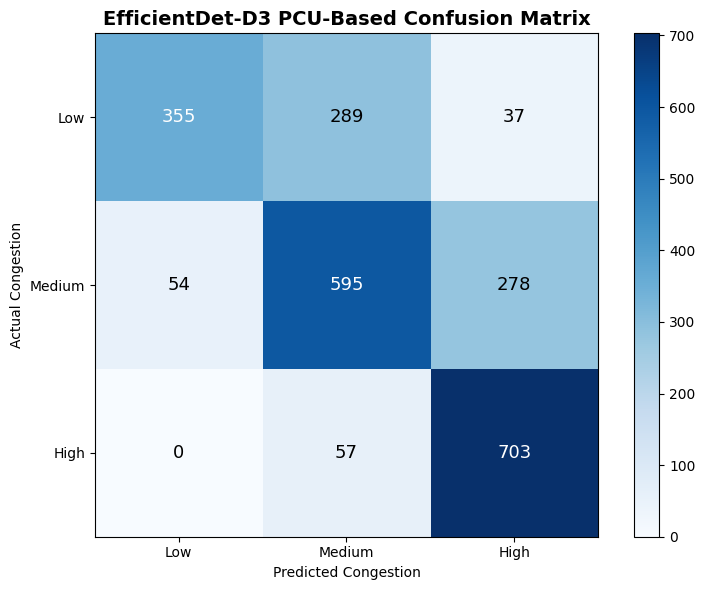

In [12]:
# ==========================================
# CONFUSION MATRIX PLOT
# ==========================================

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm, cmap="Blues")

ax.set_title(
    "EfficientDet-D3 PCU-Based Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Predicted Congestion")
ax.set_ylabel("Actual Congestion")

ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(3):

    for j in range(3):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i, j] > cm.max() / 2
                else "black"
            ),
            fontsize=13
        )

plt.colorbar(im, ax=ax)

plt.tight_layout()

plt.show()

In [13]:
# ==========================================
# CLASSIFICATION METRICS
# ==========================================

report_dict = classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).transpose()

print("EfficientDet-D3 Classification Report")

display(report_df.round(4))

print(
    "\nOverall Accuracy:",
    f"{accuracy * 100:.2f}%"
)

EfficientDet-D3 Classification Report


,precision,recall,f1-score,support
Low,0.8680,0.5213,0.6514,681.0000
Medium,0.6323,0.6419,0.6370,927.0000
High,0.6906,0.9250,0.7908,760.0000
accuracy,0.6981,0.6981,0.6981,0.6981
macro avg,0.7303,0.6960,0.6931,2368.0000
weighted avg,0.7188,0.6981,0.6905,2368.0000



Overall Accuracy: 69.81%


In [14]:
# ==========================================
# SAVE RESULTS
# ==========================================

RESULT_DIR = "/kaggle/working"

# Full PCU results
results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "efficientdet_d3_pcu_results.csv"
    ),
    index=False
)

# Classification report
report_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "efficientdet_d3_classification_report.csv"
    )
)

# Confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual_Low",
        "Actual_Medium",
        "Actual_High"
    ],
    columns=[
        "Predicted_Low",
        "Predicted_Medium",
        "Predicted_High"
    ]
)

cm_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "efficientdet_d3_confusion_matrix.csv"
    )
)

print("All result files saved successfully!")

print("\nSaved files:")

for file in os.listdir(RESULT_DIR):

    if file.startswith("efficientdet_d3_"):

        print(file)

All result files saved successfully!

Saved files:
efficientdet_d3_confusion_matrix.csv
efficientdet_d3_classification_report.csv
efficientdet_d3_pcu_results.csv
